# Check: QC'd coordinates written into the 2026_08 objects

`obs['x_um_dbscan']` / `obs['y_um_dbscan']` in the objects below were replaced
with the QC'd coordinates from `data/interim/qc_spatial_mouse.h5ad`
(`x_um_qc`/`y_um_qc`), matched by `barcode-1-sample`. Cells the spatial QC
blanked (far / degenerate / boxed / unmapped) are now `NaN`; kept cells carry
their coordinate. **Only matched (mouse) cells were changed** — the human side
of the samap joint was left as-is. Backups: `*.2026_09_01.pre_qc_coords.bak`.

The maps below are baked from the *modified* objects. The code cells reload the
objects so you can re-check in place; a final cell compares against the backup.

## XMens_All_Cells
`/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_XMens_All_Cells.h5ad`

XMens_All_Cells: n=57033  coord non-null=29544

                       n_cells  n_coord  n_blank_NaN
grp                                                 
1_dpi_early_mck1          3142     1587         1555
1_dpi_late_mck12a         6973     4077         2896
1_dpi_late_mck12b         6121     1644         4477
2_dpi_mck15               4170     2494         1676
3_dpi_mck10a              5687     3629         2058
3_dpi_mck10b              6637     4057         2580
4_dpi_bleeding_mck11a     7734     5680         2054
uninduced_mck8a           8790     3282         5508
uninduced_mck8b           7779     3094         4685


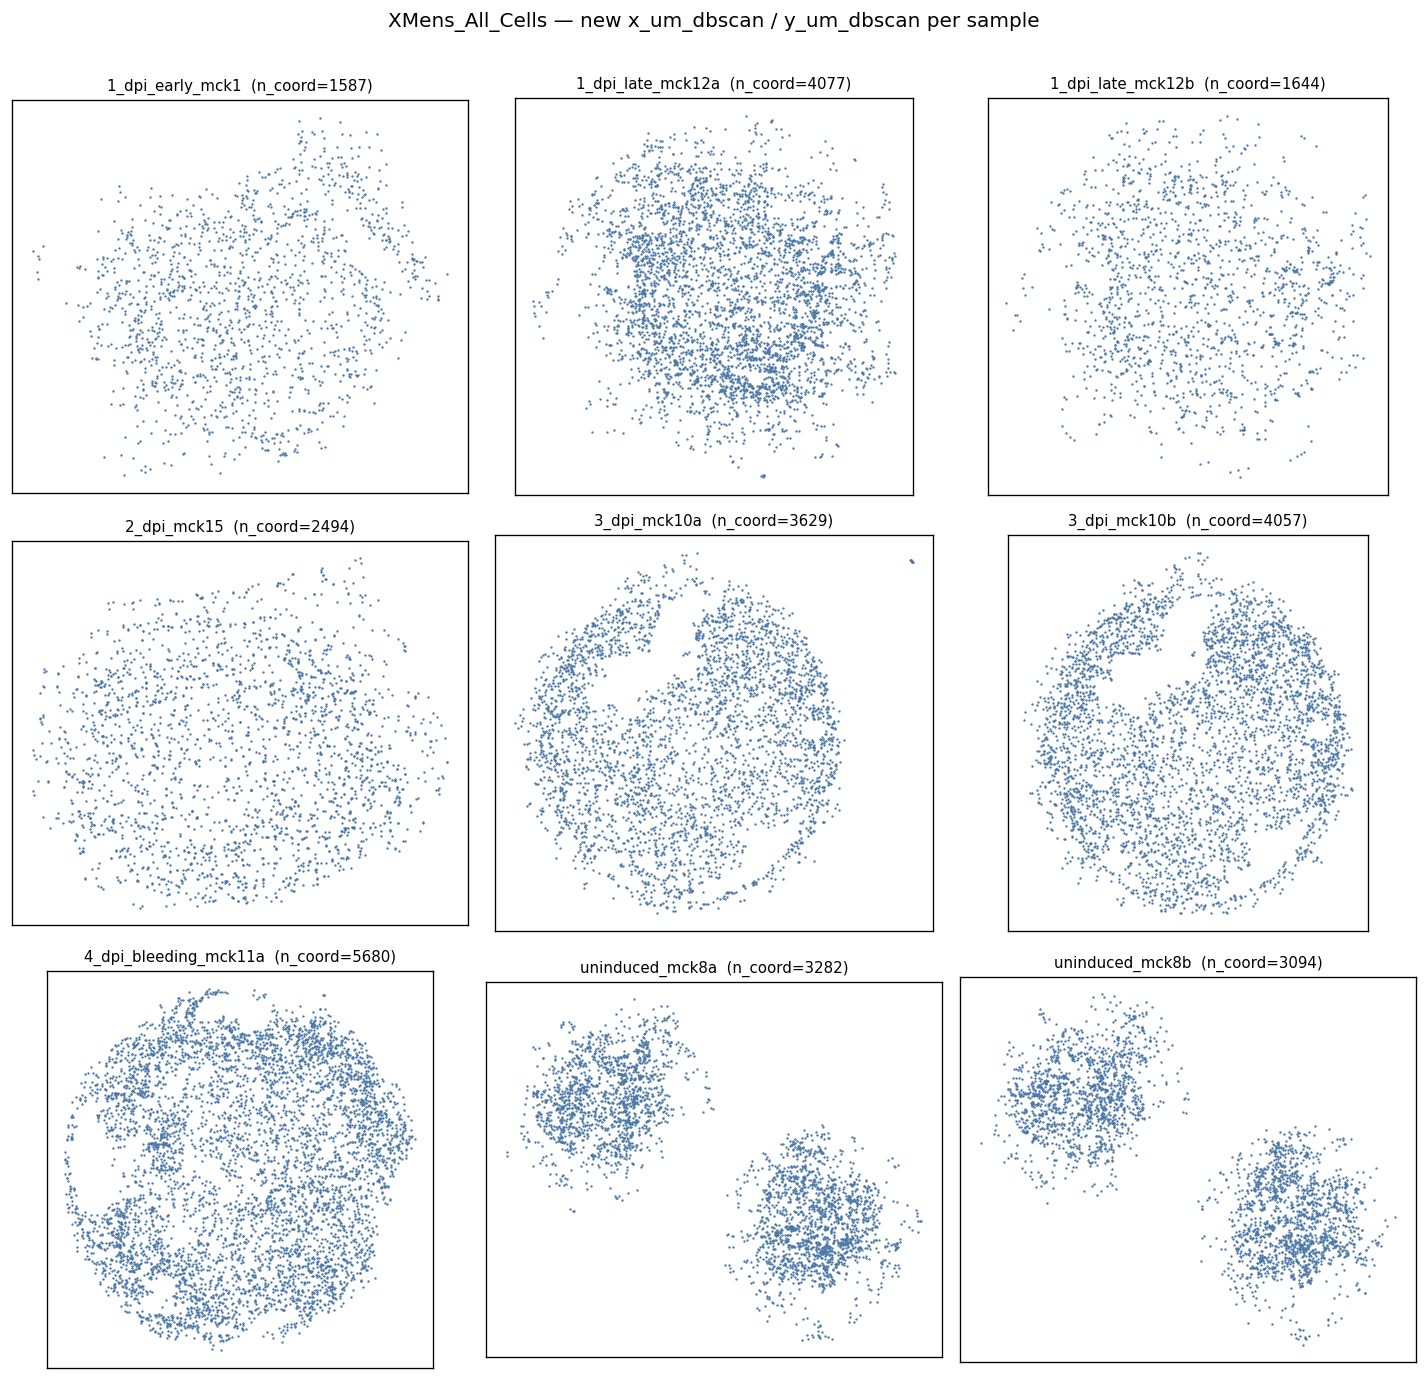

In [ ]:
import anndata as ad, numpy as np, matplotlib.pyplot as plt
a = ad.read_h5ad('/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_XMens_All_Cells.h5ad', backed='r')
obs = a.obs
x=obs['x_um_dbscan'].to_numpy().astype(float); y=obs['y_um_dbscan'].to_numpy().astype(float)
print('n=',len(obs),' coord non-null=',int(np.isfinite(x).sum()))
# per-sample spatial scatter
scol='sample' if 'sample' in obs.columns else 'timepoint'
groups=sorted(obs[scol].astype(str).unique())
import math; nc=3; nr=math.ceil(len(groups)/nc)
fig,axes=plt.subplots(nr,nc,figsize=(4*nc,3.8*nr)); axes=np.atleast_1d(axes).ravel()
for ax,g in zip(axes,groups):
    m=obs[scol].astype(str).values==g; f=np.isfinite(x[m])&np.isfinite(y[m])
    ax.scatter(x[m][f],y[m][f],s=2); ax.set_title(g,fontsize=9); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## XMens_Only_Fib_Dec
`/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad`

XMens_Only_Fib_Dec: n=43197  coord non-null=23570

                       n_cells  n_coord  n_blank_NaN
grp                                                 
1_dpi_early_mck1          2688     1395         1293
1_dpi_late_mck12a         5743     3438         2305
1_dpi_late_mck12b         5044     1445         3599
2_dpi_mck15               3574     2124         1450
3_dpi_mck10a              4938     3186         1752
3_dpi_mck10b              5735     3578         2157
4_dpi_bleeding_mck11a     6141     4518         1623
uninduced_mck8a           4991     2019         2972
uninduced_mck8b           4343     1867         2476


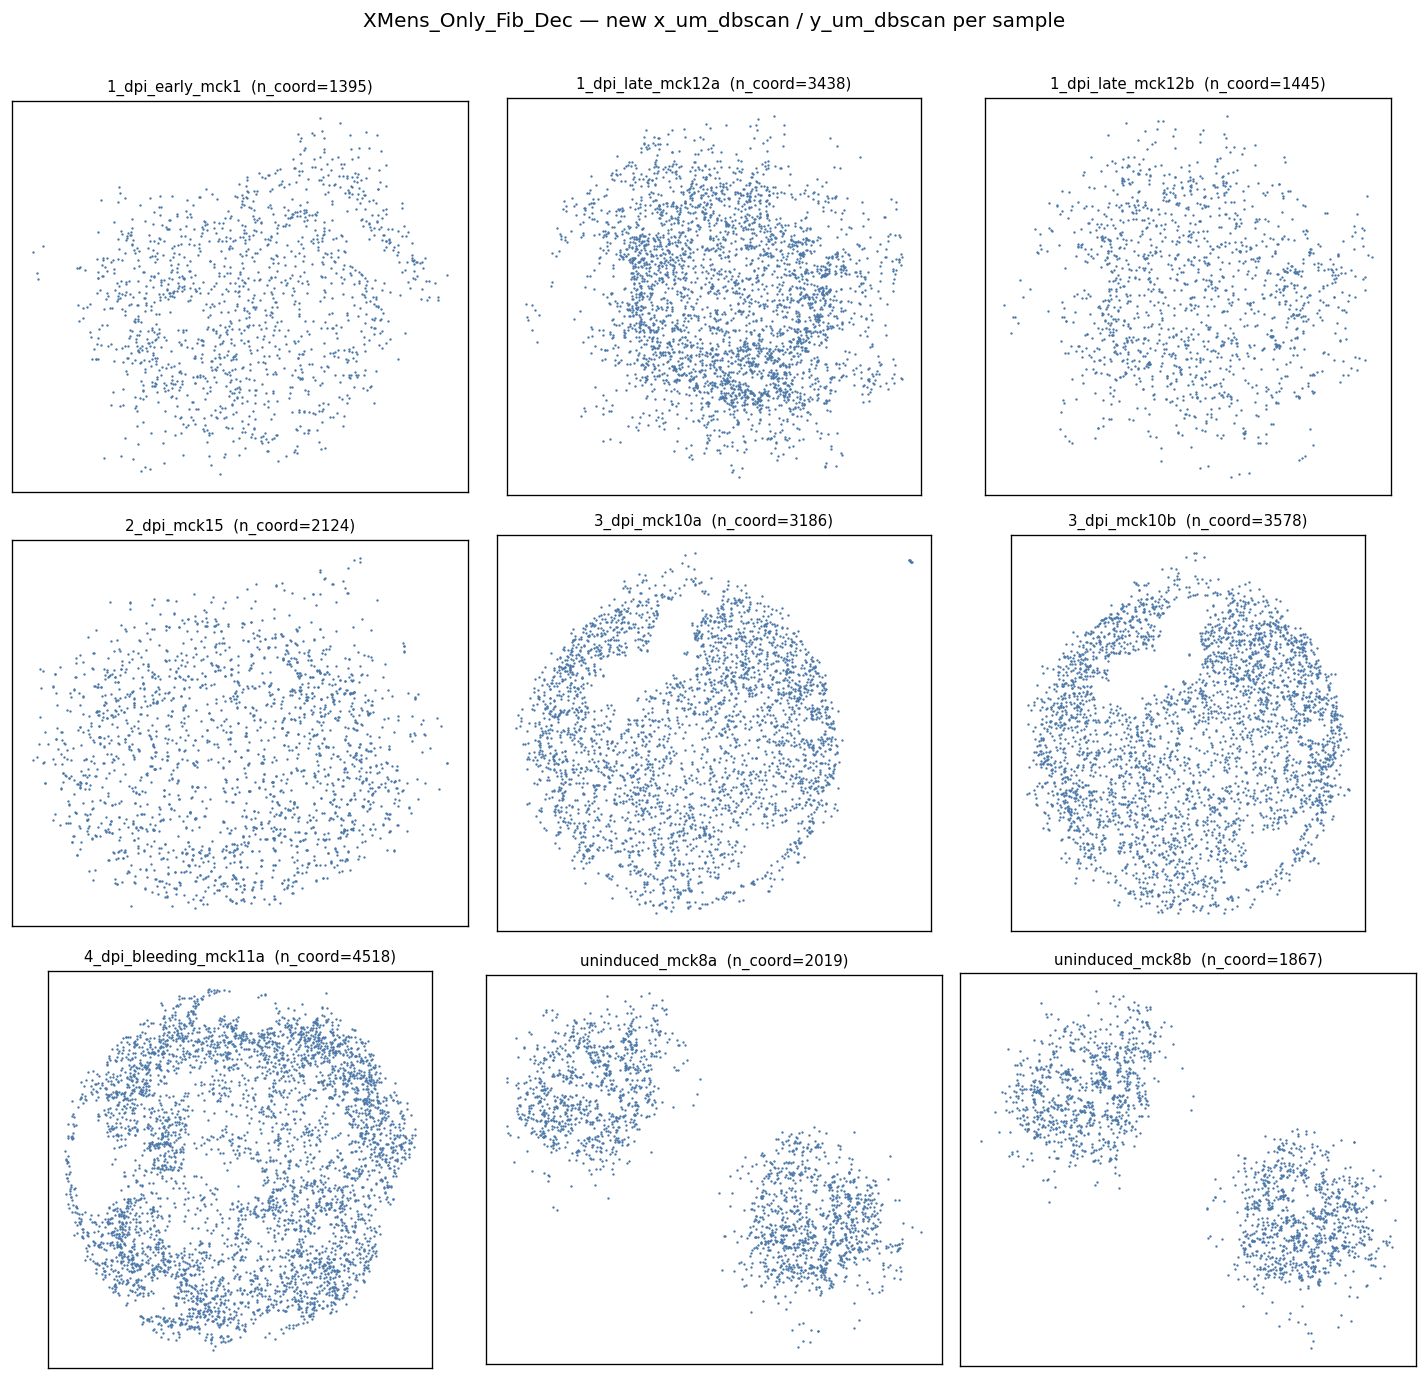

In [ ]:
import anndata as ad, numpy as np, matplotlib.pyplot as plt
a = ad.read_h5ad('/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad', backed='r')
obs = a.obs
x=obs['x_um_dbscan'].to_numpy().astype(float); y=obs['y_um_dbscan'].to_numpy().astype(float)
print('n=',len(obs),' coord non-null=',int(np.isfinite(x).sum()))
# per-sample spatial scatter
scol='sample' if 'sample' in obs.columns else 'timepoint'
groups=sorted(obs[scol].astype(str).unique())
import math; nc=3; nr=math.ceil(len(groups)/nc)
fig,axes=plt.subplots(nr,nc,figsize=(4*nc,3.8*nr)); axes=np.atleast_1d(axes).ravel()
for ax,g in zip(axes,groups):
    m=obs[scol].astype(str).values==g; f=np.isfinite(x[m])&np.isfinite(y[m])
    ax.scatter(x[m][f],y[m][f],s=2); ax.set_title(g,fontsize=9); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## samap_joint (mouse only)
`/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_31_samap_vanilla_fibdec_joint.h5ad`

samap_joint (mouse only): n=43197  coord non-null=23570

                n_cells  n_coord  n_blank_NaN
grp                                          
1_dpi_early        2688     1395         1293
1_dpi_late        10787     4883         5904
2_dpi              3574     2124         1450
3_dpi             10673     6764         3909
4_dpi_bleeding     6141     4518         1623
uninduced          9334     3886         5448


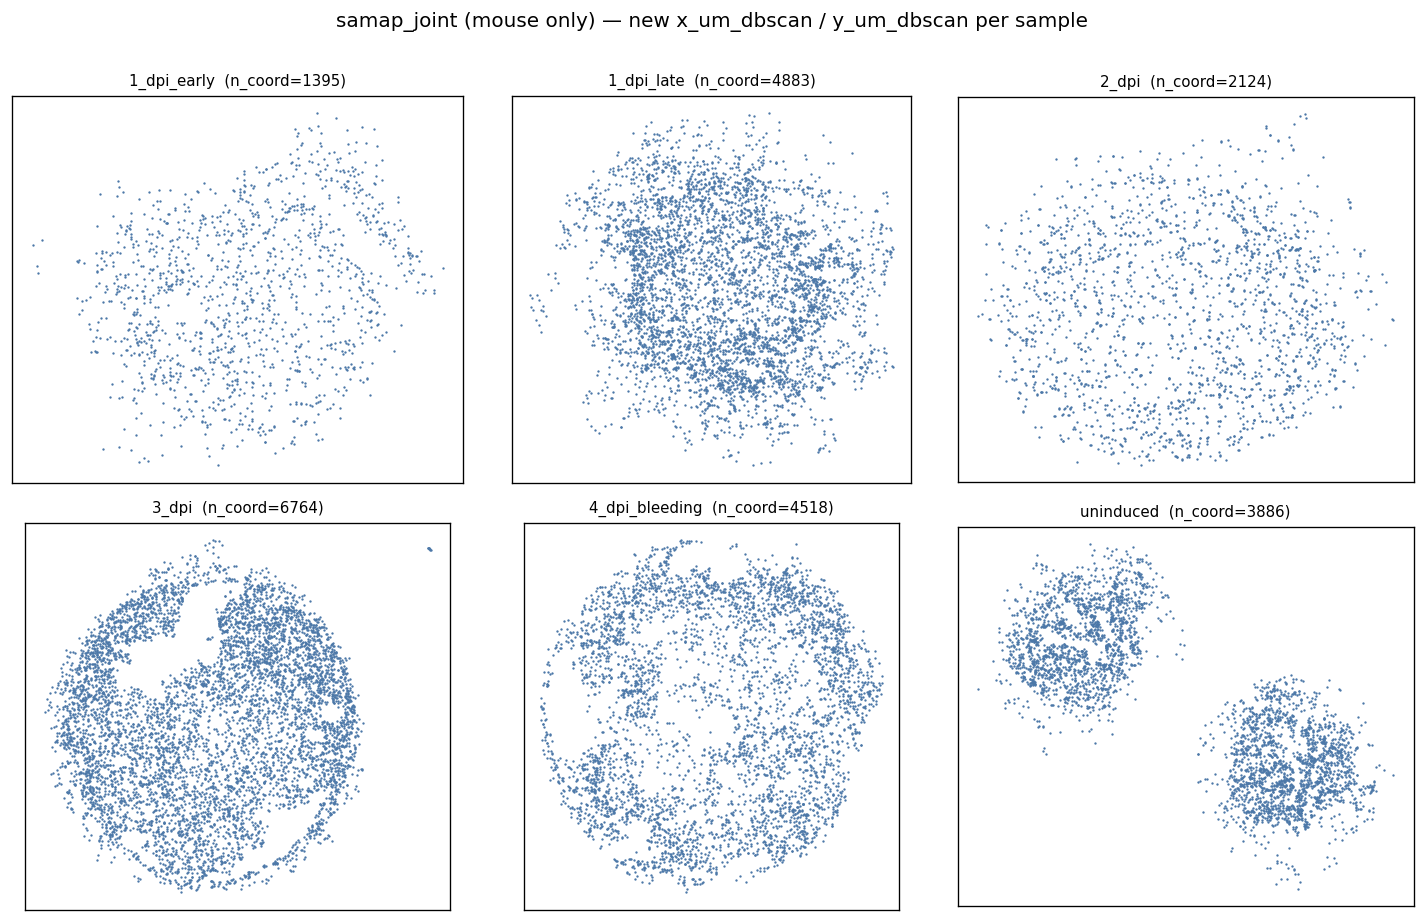

In [ ]:
import anndata as ad, numpy as np, matplotlib.pyplot as plt
a = ad.read_h5ad('/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_31_samap_vanilla_fibdec_joint.h5ad', backed='r')
obs = a.obs
obs = obs[obs['species'].astype(str).values=='mouse']
x=obs['x_um_dbscan'].to_numpy().astype(float); y=obs['y_um_dbscan'].to_numpy().astype(float)
print('n=',len(obs),' coord non-null=',int(np.isfinite(x).sum()))
# per-sample spatial scatter
scol='sample' if 'sample' in obs.columns else 'timepoint'
groups=sorted(obs[scol].astype(str).unique())
import math; nc=3; nr=math.ceil(len(groups)/nc)
fig,axes=plt.subplots(nr,nc,figsize=(4*nc,3.8*nr)); axes=np.atleast_1d(axes).ravel()
for ax,g in zip(axes,groups):
    m=obs[scol].astype(str).values==g; f=np.isfinite(x[m])&np.isfinite(y[m])
    ax.scatter(x[m][f],y[m][f],s=2); ax.set_title(g,fontsize=9); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## Compare against backup (spot-check what was blanked)

Loads the pre-patch backup and reports, per sample, how many cells that had a
coordinate before are now `NaN` (i.e. blanked by the QC).

In [ ]:
import anndata as ad, numpy as np, pandas as pd
N = '/n/netscratch/eddy_lab/Everyone/nhilgert'
pairs = [
  ("XMens_All", f"{N}/2026_08_28_Cevrim_XMens_All_Cells.h5ad"),
  ("XMens_OnlyFibDec", f"{N}/2026_08_28_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"),
]
for name, f in pairs:
    now = ad.read_h5ad(f, backed="r").obs
    bak = ad.read_h5ad(f + ".2026_09_01.pre_qc_coords.bak", backed="r").obs
    xb = bak.loc[now.index, "x_um_dbscan"].to_numpy().astype(float)
    xn = now["x_um_dbscan"].to_numpy().astype(float)
    blanked = np.isfinite(xb) & ~np.isfinite(xn)
    df = pd.DataFrame({"sample": now["sample"].astype(str).values, "blanked": blanked})
    print(name, "total blanked:", int(blanked.sum()))
    print(df.groupby("sample")["blanked"].sum().to_string()); print()
